In [2]:
import seaborn as sb
import numpy as np
import random
import math
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import functools as ft
import statistics
import scipy as sc
import pingouin as ping
import hyppo as hyp

In [ ]:
дана мпи
Найти м.в.п. вложенной цепи, моделировать Xt с помощью вложенной цепи.

0.0 0.25 0.75 

0.6666666666666666 0.0 0.3333333333333333 

0.6666666666666666 0.3333333333333333 0.0 





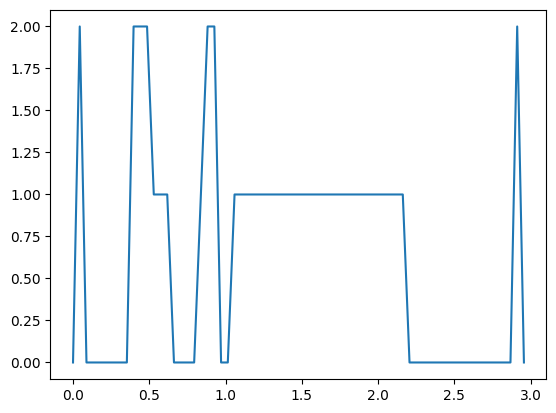

In [5]:
def print_mat(a):
    n = len(a)
    for i in range(n):
        for j in range(n):
            print (a[i][j], end = " ")
        print("\n")
    print("\n")  

def chain(p, n, p_0):
    x = [-1]*n
    s = len(p[0])
    vals = [j for j in range(s)]
    x[0] = int(np.random.choice(vals, p=p_0))
    for k in range(1,n):
        x[k] = int(np.random.choice(vals, p=p[x[k-1]]))
    return x

def jump(q):
    n = len(q)
    p = [[0 for _ in range(n)] for j in range(n)]
    for i in range (n):
        for j in range (n):
            if i!=j:
                p[i][j] = -q[i][j]/q[i][i]
    for k in range(n):
        p[k][k] = 1 - np.sum(p[k])
    return p

def mprocess(q, p, p_0, n, chain):
    x = chain(p, n, p_0)
    nu = [np.random.exponential(scale = -1/q[l][l], size = 1)[0] for l in x]
    return x, nu

def f(t, x, nu):
    n = len(x)
    if np.sum(nu) < t:
        print("процесс не дожил")
        return -1
    for k in range(n):
        time = 0
        for j in range(k):
            time += nu[j]
        if time > t:
            return x[j]
    
n = 20 # число скачков цепи
q = [ [-4, 1, 3], [2/3, -1, 1/3], [12, 6, -18] ]
p = jump(q)
print_mat(p)

x, nu = mprocess(q, p, [1/3, 1/3, 1/3], n, chain)
l = np.linspace(0, np.sum(nu), 100)
plt.plot(l, [f(t, x, nu) for t in l])

In [ ]:
Пусть Xt – марковский процесс с интенсивностью перехода i
2 из состояния i в i + 1. Моделировать
процесс и построить его траекторию. Что мы наблюдаем в нашем процессе?

In [ ]:
Q: 
-1 1 0 0
0 -4 4 0
0 0 -9 9
...

P:
0 1 0 0 
0 0 1 0
0 0 0 1

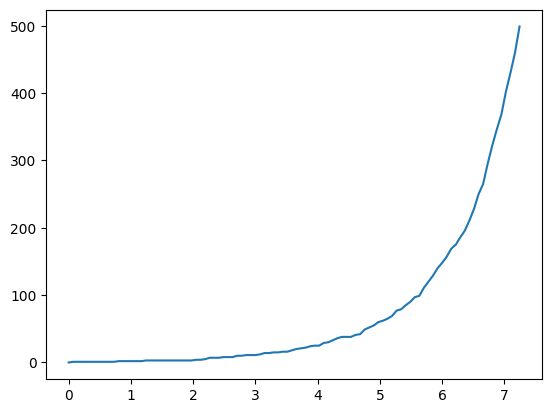

In [15]:
def print_mat(a):
    n = len(a)
    for i in range(n):
        for j in range(n):
            print (a[i][j], end = " ")
        print("\n")
    print("\n")  

def X(t, nu):
    k = 0
    if np.sum(nu) < t:
        print("процесс не дожил")
        return -1
    while np.sum( [nu[j] for j in range(k)] ) < t:
        k += 1
    return k
n = 500
nu = [np.random.exponential(scale = 1/l**(1), size = 1)[0] for l in range(1, n)]
l = np.linspace(0, np.sum(nu), 100)
plt.plot(l, [X(t, nu) for t in l])

In [ ]:
3. В парикмахерскую с тремя парикмахерами приходят клиенты с интенсивностью λ, парикмахеры об-
служивают клиентов с интенсивностью μ. Если все парикмахеры заняты, то клиент садится в очередь.

Моделировать процесс при а) λ = 1, μ = 1, б) λ = 4, μ = 1.

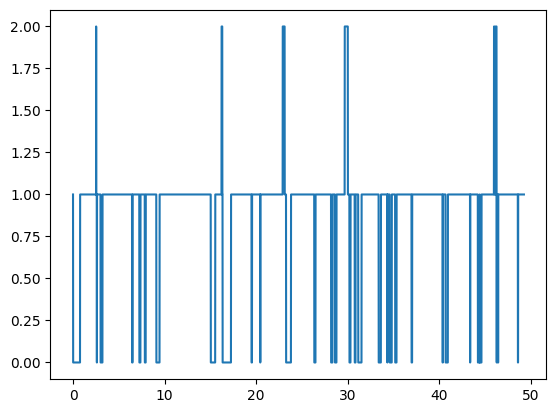

In [4]:
def hair_salon (lamda, mu, n):# n - длина процесса. изначально 0 клиентов 
    x = [0]*n
    time = [0]*n
    time[0] = np.random.exponential(scale = 1/lamda)
    for k in range(n-1):
        if x[k] < 3:
            x[k+1] = x[k] + 2*(np.random.binomial(1, lamda/(lamda + x[k]*mu)) - 1/2)
            time[k+1] = np.random.exponential(scale = 1/(lamda + x[k]*mu))
        else:
            x[k+1] = x[k] + 2*(np.random.binomial(1, lamda/(lamda + 3*mu)) - 1/2)
            time[k+1] = np.random.exponential(scale = 1/(lamda + 3*mu))
    return x, time

def X(t, nu, x):
    k = 0
    if np.sum(nu) < t:
        print("процесс не дожил")
        return -1
    while np.sum( [nu[j] for j in range(k)] ) < t:
        k += 1
    return x[k-1]


n = 80
lamda = 1
mu = 4

x, nu = hair_salon (lamda, mu, n)
#print(x)
l = np.linspace(0, np.sum(nu), 10000)
plt.plot(l, [X(t, nu, x) for t in l])

In [ ]:
дана мпи
Найдем стационарное распределение Q и сравним его со стационарными распределениями двух марков-
ских цепей а) вложенной цепи б*) цепи, полученной измерением ЦМ через независимые exp(1) времена.

Для оценки стационарного распределения марковских цепей будем считать долю времени, проведенного
цепью в каждом из состояний за длительное время.



In [29]:
def print_mat(a):
    n = len(a)
    for i in range(n):
        for j in range(n):
            print (a[i][j], end = " ")
        print("\n")
    print("\n")  

def chain(p, n, p_0):
    x = [-1]*n
    s = len(p[0])
    vals = [j for j in range(s)]
    x[0] = int(np.random.choice(vals, p=p_0))
    for k in range(1,n):
        x[k] = int(np.random.choice(vals, p=p[x[k-1]]))
    return x

def jump(q):
    n = len(q)
    p = [[0 for _ in range(n)] for j in range(n)]
    for i in range (n):
        for j in range (n):
            if i!=j:
                p[i][j] = -q[i][j]/q[i][i]
    for k in range(n):
        p[k][k] = 1 - np.sum(p[k])
    return p

def mprocess(q, p, p_0, n, chain):
    x = chain(p, n, p_0)
    nu = [np.random.exponential(scale = -1/q[l][l], size = 1)[0] for l in x]
    return x, nu

def f(t, x, nu):
    n = len(x)
    if np.sum(nu) < t:
        print("процесс не дожил")
        return -1
    for k in range(n):
        time = 0
        for j in range(k):
            time += nu[j]
        if time > t:
            return x[j]

def stationary_d(a):
    s = -1
    vals, vect = sc.linalg.eig(a, left = True, right = False)
    for k in range (len(vals)):
        if np.abs(vals[k]- 1) <= 1/1000:
            s = k
    return vect[:, s] / np.sum(vect[:, s])

def stationary_hat(x, nu, s):
    n = len(x)
    pi = [0]*s
    for k in range(n):
        pi[x[k]] += nu[k]/np.sum(nu)
    return pi
    
n = 1500 # число скачков цепи
q = [ [-5, 1, 3, 1], [1, -3, 1 , 1], [3, 1, -5, 1], [1, 1, 1, -3] ]
p = jump(q)

print("вложенная:")
print_mat(p)

print("стац распр вложеннной\n",stationary_d(p))

x, nu = mprocess(q, p, [1/4]*4, n, chain)
pi = stationary_hat(x, nu,  4)
print("оценка стац распр процесса\n", pi, "хотя ту очев стац распр процееса равномерное тк по солбцу сумма 0")

"""
l = np.linspace(0, np.sum(nu), n)
plt.plot(l, [f(t, x, nu) for t in l])
"""

nu_1 = np.random.exponential(scale = 1, size = int(n/2))
x_new = [-1]*int(n/2)

for k in range(int(n/2)):
    t = np.sum(nu[:k:])
    x_new[k] = f(t, x, nu)

pi_new = stationary_hat(x_new, nu_1,  4)
print("оценка стац распр цепи, полученной измерением ЦМ через независимые exp(1) времена\n", pi_new)

вложенная:
0.0 0.2 0.6 0.2 

0.3333333333333333 0.0 0.3333333333333333 0.3333333333333333 

0.6 0.2 0.0 0.2 

0.3333333333333333 0.3333333333333333 0.3333333333333333 0.0 



стац распр вложеннной
 [0.3125 0.1875 0.3125 0.1875]
оценка стац распр процесса
 [np.float64(0.24653056076309335), np.float64(0.24290465043355172), np.float64(0.2595232770429516), np.float64(0.25104151176040335)] хотя ту очев стац распр процееса равномерное тк по солбцу сумма 0
оценка стац распр цепи, полученной измерением ЦМ через независимые exp(1) времена
 [np.float64(0.31564833909150586), np.float64(0.16848228892110573), np.float64(0.328906646089481), np.float64(0.1869627258979071)]


In [ ]:
5. * В файле nerve.txt содержатся промежутки между нервными импульсами, проходящими по нейронам.

Основная гипотеза заключается в том, что они независимые экспоненциальные. Построим процесс, кото-
рый подпрыгивает на 1 через наши промежутки. Проверим, что длительность пребывания в состоянии

с начала и до конца такая же как ”оставшаяся”. Иначе говоря, возьмем исходную последовательность
промежутков и построим ее гистограмму, а также выберем случайные точки на прямой (равномерно
на накрытой промежутками части) и для каждой рассмотрим оставшееся время до ближайшего скачка
нашего процесса, у полученного набора оставшихся времен построим гистограмму. Будут ли две наших
гистограммы похожи (то есть выполнено ли свойство ”новое такое же как старое”? Проверить эти две
последовательности на однородность по критерию Манна-Уитни-Уилкоксона.

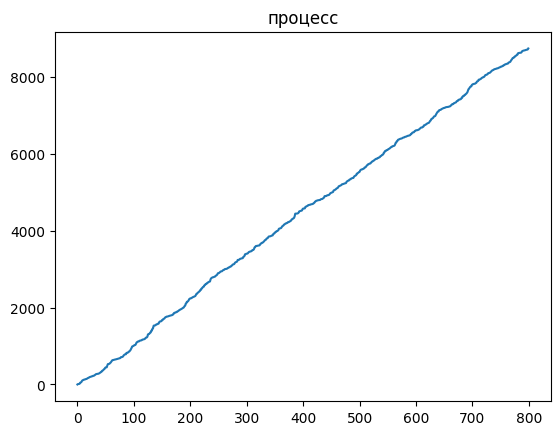

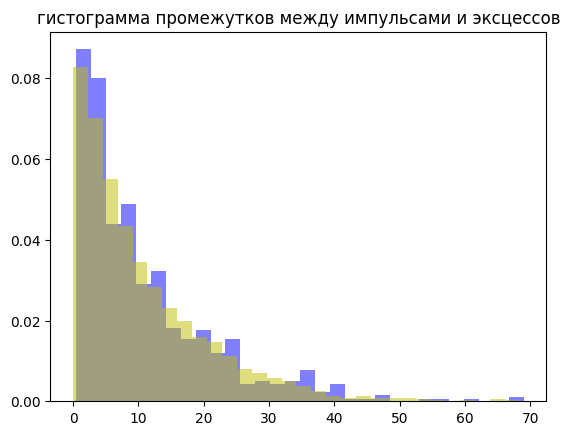

0.11185622589371247


In [81]:
nerve = np.loadtxt('nerve.txt')
n = np.size(nerve)
jumps = [np.sum(nerve[:l:]) for l in range(n+1)]
plt.plot([i for i in range(n+1)],jumps)
plt.title("процесс")
plt.show()
n +=1

m = 8000 # сколько равномерных точек кидаю
u = np.random.uniform(0, np.max(jumps), size = m)

excesses = [-1]*m
for k in range(m):
    c = 0
    while u[k] > jumps[c] and c<n-1:
        c+=1
    excesses[k] = jumps[c] - u[k]

plt.hist(nerve, bins = 30, density = "true", color = "b", alpha = 0.5)
plt.hist(excesses, bins = 30,density = "true", color = "y", alpha = 0.5)
plt.title("гистограмма промежутков между импульсами и эксцессов")
plt.show()

print(sc.stats.mannwhitneyu(nerve, excesses, alternative='greater', method = "asymptotic").pvalue)